# 04 — Peningkatan model
Skor leaderboard baseline yang dilaporkan pengguna pada 27 Oktober 2026: **0,67294**. Eksperimen lanjutan menggunakan EfficientNet-B0 pretrained ImageNet pada 224×224. Model ini memperoleh skor leaderboard **0,85236**, dilaporkan pengguna pada 28 Oktober 2026. Satu holdout identik dipakai untuk perbandingan; eksperimen berikutnya tersedia pada notebook 05.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/efficientnet_improved'
display(json.loads((ROOT / 'configs/efficientnet_improved.json').read_text()))
display(pd.read_json(ROOT / 'reports/leaderboard_history.json'))

{'run_name': 'efficientnet_improved',
 'model': 'efficientnet_b0',
 'pretrained': True,
 'image_size': 224,
 'epochs': 8,
 'batch_size': 32,
 'learning_rate': 0.0003,
 'weight_decay': 0.01,
 'label_smoothing': 0.05,
 'patience': 3,
 'seed': 42,
 'validation_fraction': 0.2,
 'workers': 2,
 'threads': 4,
 'amp': True,
 'selection_metric': 'accuracy'}

,reported_on,run_name,submission,submission_sha256,score,score_source,leaderboard_partition,metric_name
0,2026-10-27,baseline_cnn,submissions/submission_baseline.csv,5fd9913aedf081fdb66e9823eb28e36e6146162113f3d1...,0.67294,Reported by user in chat,unspecified,unverified
1,2026-10-28,efficientnet_improved,submissions/submission_improved.csv,2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80...,0.85236,Reported by user in chat,unspecified,unverified


## Metode
Semua layer EfficientNet di-fine-tune dengan AdamW dan cosine schedule. Piksel diproses dengan letterbox grayscale, direplikasi ke tiga kanal, lalu dinormalisasi ImageNet. CUDA mixed precision mempercepat training. Tidak ada lookup label test. Inisialisasi pretrained berasal dari ImageNet; fine-tuning menggunakan training split kompetisi ini.

Jalankan python -m scripts.preprocess --image-size 224, lalu python -m scripts.train --config configs/efficientnet_improved.json --device cuda dari environment CUDA. Artefak baseline dipertahankan.

In [2]:
assert (RUN / 'metrics.json').exists(), 'Jalankan training EfficientNet lebih dahulu'
from scripts.compare_runs import compare_runs
comparison = compare_runs()
display(pd.read_csv(RUN / 'comparison.csv'))
display(json.loads((RUN / 'run.json').read_text()))

                  run  accuracy  macro_f1  validation_rows  best_epoch
         baseline_cnn  0.680375  0.673017             6395           5
efficientnet_improved  0.854418  0.853316             6395           8
{
  "reference": "baseline_cnn",
  "candidate": "efficientnet_improved",
  "identical_split": true,
  "accuracy_gain_percentage_points": 17.404222048475372,
  "macro_f1_gain": 0.18029905674168345,
  "corrected_errors": 1312,
  "new_errors": 199,
  "both_correct": 4152,
  "both_wrong": 732,
  "classes_with_f1_improvement": 16,
  "candidate_leaderboard_score": 0.85236,
  "recommended_run": "efficientnet_improved"
}


,run,accuracy,macro_f1,validation_rows,best_epoch
0,baseline_cnn,0.680375,0.673017,6395,5
1,efficientnet_improved,0.854418,0.853316,6395,8


{'config': {'run_name': 'efficientnet_improved',
  'model': 'efficientnet_b0',
  'pretrained': True,
  'image_size': 224,
  'epochs': 8,
  'batch_size': 32,
  'learning_rate': 0.0003,
  'weight_decay': 0.01,
  'label_smoothing': 0.05,
  'patience': 3,
  'seed': 42,
  'validation_fraction': 0.2,
  'workers': 2,
  'threads': 4,
  'amp': True,
  'selection_metric': 'accuracy'},
 'device': 'cuda',
 'versions': {'torch': '2.11.0+cu128',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.10.7',
  'torchvision': '0.26.0+cu128'},
 'device_name': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'train_rows': 25607,
 'validation_rows': 6395,
 'metadata_digest': '7d3d83196e1e9ae8aad8d980fbe579e496da5999e2e36f2622f0eeb4d08b179e',
 'parameter_count': 4028044}

## Learning curves dan perubahan per kelas
Periksa peningkatan accuracy dan macro-F1, bukan hanya training loss. Epoch terbaik dipilih pada holdout yang sama; hasil ini belum merupakan evaluasi independen setelah tuning. Perubahan backbone dan resolusi dilakukan bersamaan sehingga kontribusi masing-masing belum diisolasi.

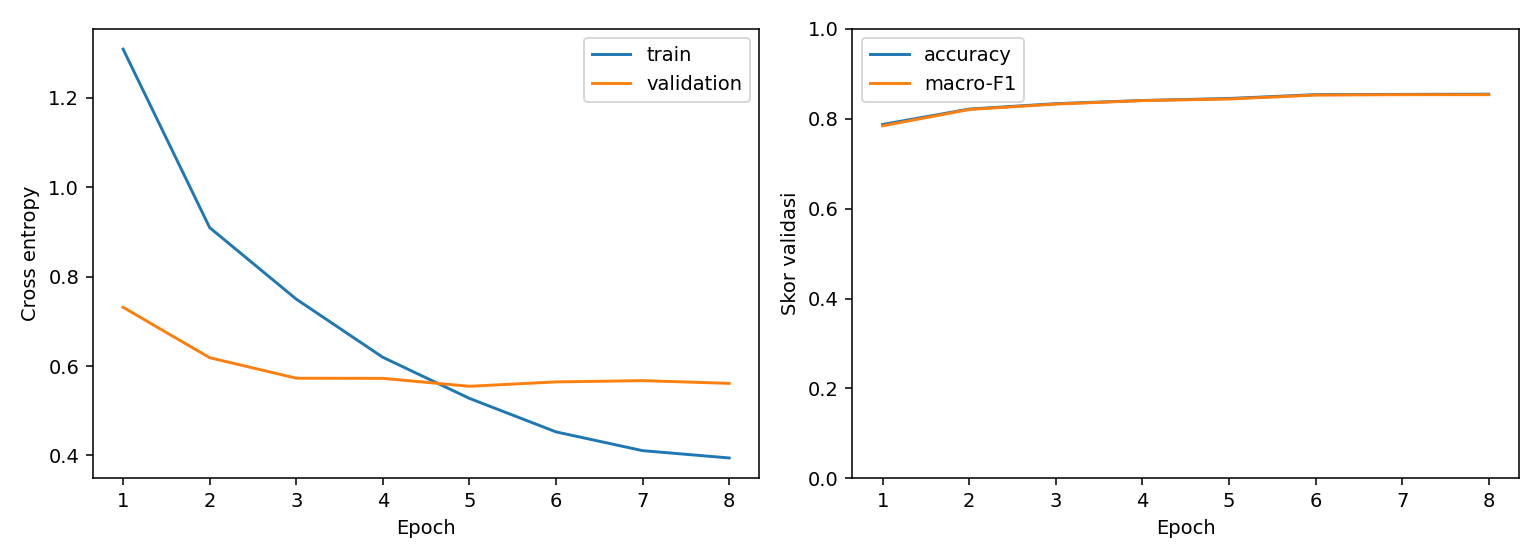

,class_name,baseline_f1,candidate_f1,delta_f1
5,handwritten,0.861171,0.933941,0.072769
2,email,0.894872,0.968750,0.073878
3,file_folder,0.834423,0.920598,0.086176
0,advertisement,0.776413,0.873762,0.097350
12,resume,0.820690,0.928571,0.107882
15,specification,0.769018,0.911051,0.142033
9,news_article,0.733601,0.878173,0.144572
13,scientific_publication,0.774942,0.921053,0.146111
10,presentation,0.565267,0.725220,0.159953
7,letter,0.651282,0.857523,0.206241


{'reference': 'baseline_cnn',
 'candidate': 'efficientnet_improved',
 'identical_split': True,
 'accuracy_gain_percentage_points': 17.404222048475372,
 'macro_f1_gain': 0.18029905674168345,
 'corrected_errors': 1312,
 'new_errors': 199,
 'both_correct': 4152,
 'both_wrong': 732,
 'classes_with_f1_improvement': 16,
 'candidate_leaderboard_score': 0.85236,
 'recommended_run': 'efficientnet_improved'}

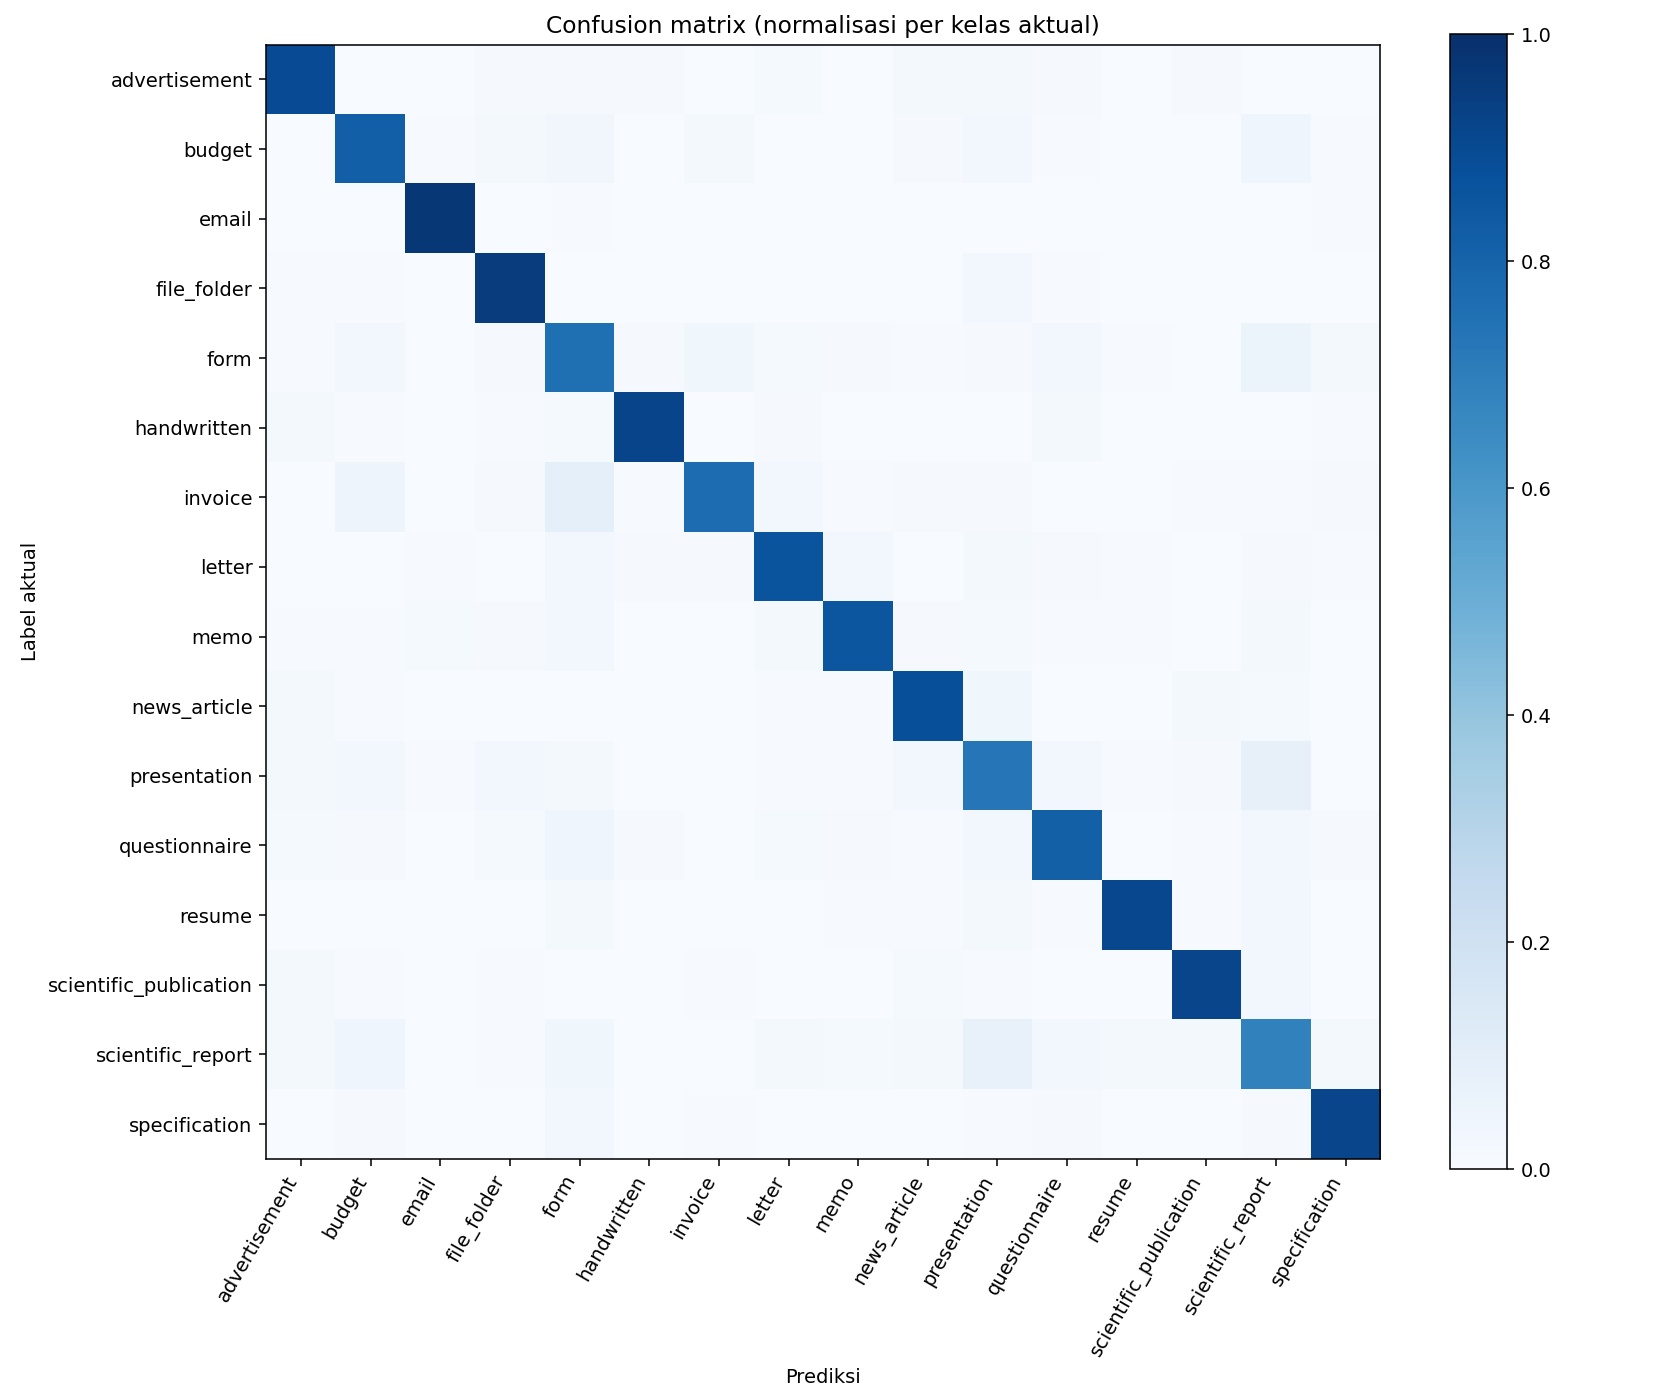

In [3]:
display(Image(filename=str(RUN / 'learning_curves.png')))
display(pd.read_csv(RUN / 'class_comparison.csv').sort_values('delta_f1'))
display(comparison)
display(Image(filename=str(RUN / 'confusion_matrix.png')))

## Submission kandidat
Gunakan checkpoint dengan accuracy validasi tertinggi. Prediksi tetap diurutkan mengikuti ID sample submission. Kenaikan skor lokal tidak menjamin kenaikan yang identik di leaderboard.

In [4]:
from scripts.predict import validate_submission
submission = pd.read_csv(ROOT / 'submissions/submission_improved.csv')
from scripts.preprocess import read_metadata, data_directory
_, _, sample = read_metadata(data_directory())
validate_submission(submission, sample)
print(f'Valid: {len(submission)} rows')
display(submission.head())
display(json.loads((ROOT / 'reports/submission_improved_provenance.json').read_text()))

Valid: 7994 rows


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,1
4,test_00005,13


{'checkpoint': 'checkpoint\\efficientnet_improved\\best.pt',
 'checkpoint_sha256': 'd8d9c6d97f01e5d982f182afdeba3b2496b514e062d0e1087dcddfdb153e1e7b',
 'submission_sha256': '2b6a2963be747cb4f3eb84e73ec0b162e22864b38e8f80f20291eb4bd24cb41f',
 'rows': 7994,
 'label_counts': {'0': 511,
  '1': 493,
  '2': 508,
  '3': 538,
  '4': 557,
  '5': 491,
  '6': 467,
  '7': 499,
  '8': 484,
  '9': 488,
  '10': 521,
  '11': 462,
  '12': 501,
  '13': 503,
  '14': 476,
  '15': 495},
 'best_epoch': 8,
 'validation_metrics': {'val_loss': 0.5612805870569153,
  'accuracy': 0.8544175136825645,
  'macro_f1': 0.8533156811409401},
 'public_score': None,
 'private_score': None,
 'reported_leaderboard_score': 0.85236,
 'score_reported_on': '2026-10-28',
 'score_source': 'User report; leaderboard partition unspecified'}